# EDA: разведочный анализ данных

## Импорты

In [1]:
from pathlib import Path

In [2]:
from sklearn.preprocessing import LabelEncoder
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

In [3]:
from src.dataset import DatasetStore

In [4]:
import warnings
warnings.filterwarnings('ignore')

## Загрузка данных

In [5]:
df, schema = DatasetStore.load(
    "data/processed/dataset.csv",
    "data/processed/dataset.schema.json",
    include_missing=False,
)
feature_info = DatasetStore.get_feature_info(
    schema,
    include_missing=False,
)
target = "diagnosis"

## 1. Общая информация

In [6]:
df.info()

print('\nИспользование памяти:')
print(df.memory_usage(deep=True).sum() / 1024, 'KB')

<class 'pandas.DataFrame'>
RangeIndex: 392 entries, 0 to 391
Data columns (total 43 columns):
 #   Column           Non-Null Count  Dtype   
---  ------           --------------  -----   
 0   Sex              392 non-null    category
 1   Age              392 non-null    category
 2   Ds naprav        392 non-null    category
 3   time disease     392 non-null    category
 4   chr pancr        392 non-null    category
 5   soput disease    392 non-null    category
 6   compens          392 non-null    category
 7   pain             392 non-null    category
 8   intensiv         392 non-null    category
 9   rvota            392 non-null    category
 10  cofe gugha       392 non-null    category
 11  slabost          392 non-null    category
 12  ogirenie         392 non-null    category
 13  t                392 non-null    category
 14  encef            392 non-null    category
 15  bled cut         347 non-null    category
 16  mramor cut       392 non-null    category
 17  icterus 

## 2. Пропущенные значения

In [7]:
missing = pd.DataFrame({
    'count': df.isna().sum(),
    'pct': (df.isna().sum() / len(df) * 100).round(2),
    'dtype': df.dtypes.astype(str),
}).sort_values('count', ascending=False)

missing_only = missing[missing['count'] > 0]
print(f'Столбцов с пропусками: {len(missing_only)} из {df.shape[1]}')
print(f'Всего пропущенных ячеек: {df.isna().sum().sum()}')
missing_only

Столбцов с пропусками: 2 из 43
Всего пропущенных ячеек: 94


,count,pct,dtype
albumin,49,12.50,category
bled cut,45,11.48,category


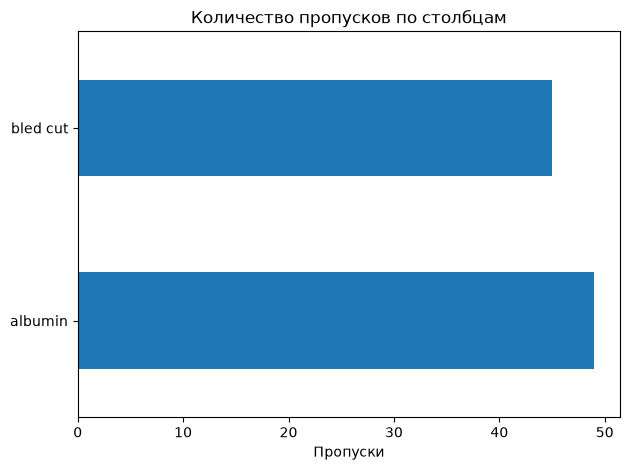

In [8]:
if len(missing_only) > 0:
    missing_only['count'].plot(kind='barh', title='Количество пропусков по столбцам')
    plt.xlabel('Пропуски')
    plt.tight_layout()
    plt.show()

## 3. Целевая переменная

,count,pct
diagnosis,,
1,239,60.97
5,86,21.94
6,67,17.09


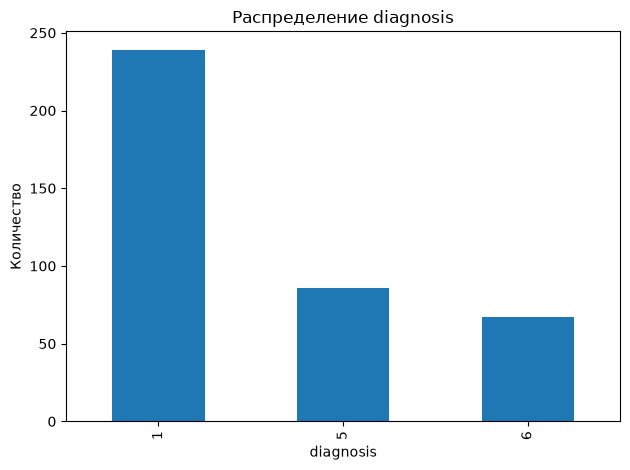

In [9]:
vc = df[target].value_counts(dropna=False).to_frame('count')
vc['pct'] = (vc['count'] / len(df) * 100).round(2)
display(vc)

vc['count'].plot(kind='bar', title=f'Распределение {target}')
plt.ylabel('Количество')
plt.tight_layout()
plt.show()

## 4. Уникальные значения и константные признаки

In [10]:
uniq = pd.DataFrame({
    'n_unique': df.nunique(dropna=False),
    'n_unique_no_na': df.nunique(dropna=True),
    'dtype': df.dtypes.astype(str),
}).sort_values('n_unique')

constant_cols = uniq[uniq['n_unique_no_na'] <= 1].index.tolist()
print('Константные столбцы:', constant_cols if constant_cols else 'нет')
uniq

Константные столбцы: ['bled cut']


,n_unique,n_unique_no_na,dtype
Sex,2,2,category
Ds naprav,2,2,category
time disease,2,2,category
chr pancr,2,2,category
soput disease,2,2,category
cofe gugha,2,2,category
rvota,2,2,category
intensiv,2,2,category
ogirenie,2,2,category
bled cut,2,1,category


## 6. Унивариативный анализ признаков

In [11]:
def plot_feature_distribution(col, top_n=20):
    if col not in df.columns or col == target:
        return
    vc = df[col].value_counts(dropna=False).head(top_n)
    if len(vc) == 0:
        return
    plt.figure(figsize=(10, max(3, len(vc) * 0.4)))
    sns.barplot(x=vc.values, y=vc.index.astype(str), orient='h')
    plt.title(f'Распределение признака: {col}')
    plt.xlabel('Количество')
    plt.ylabel('')
    plt.tight_layout()
    plt.show()

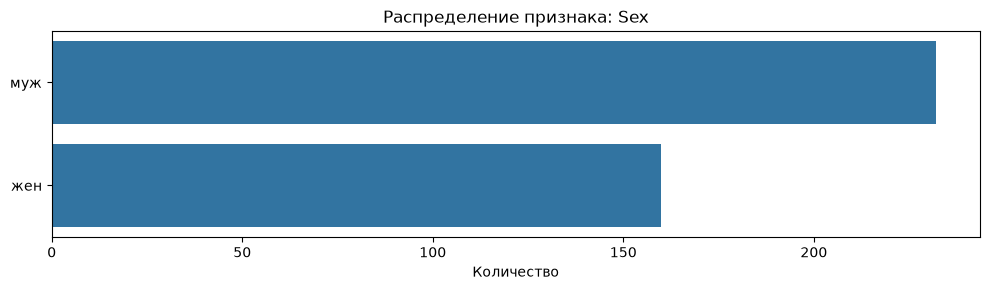

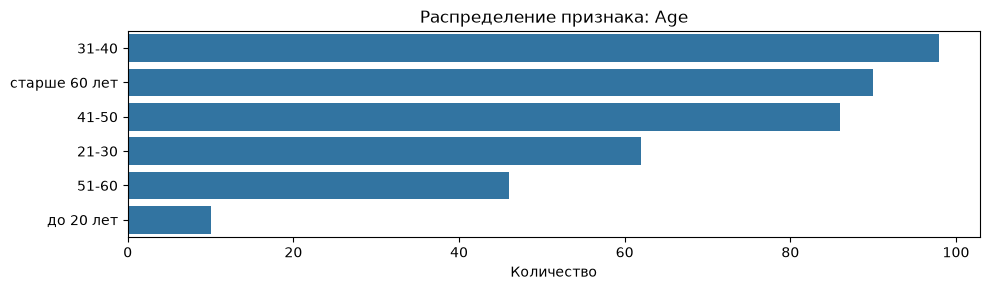

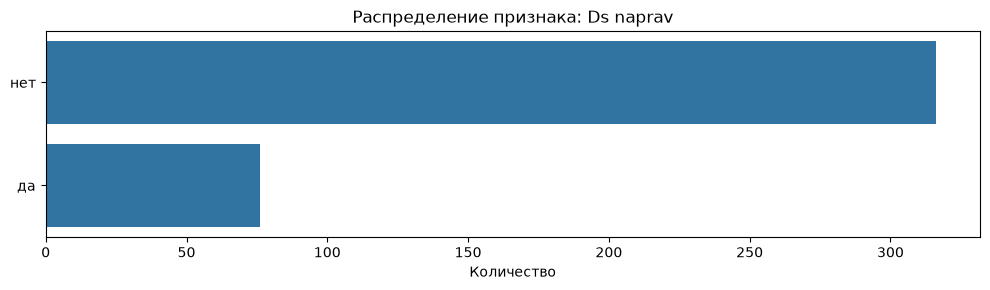

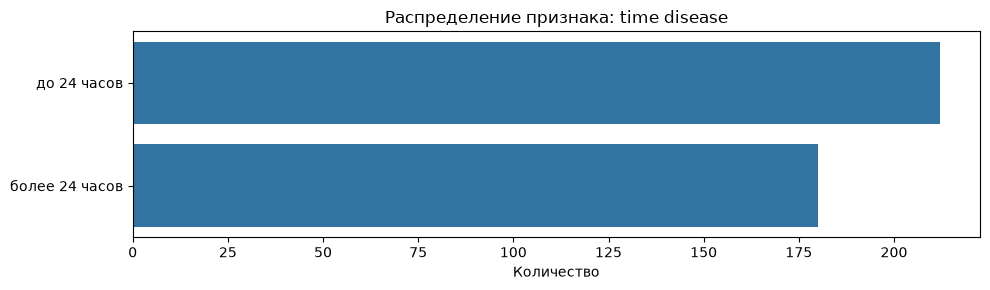

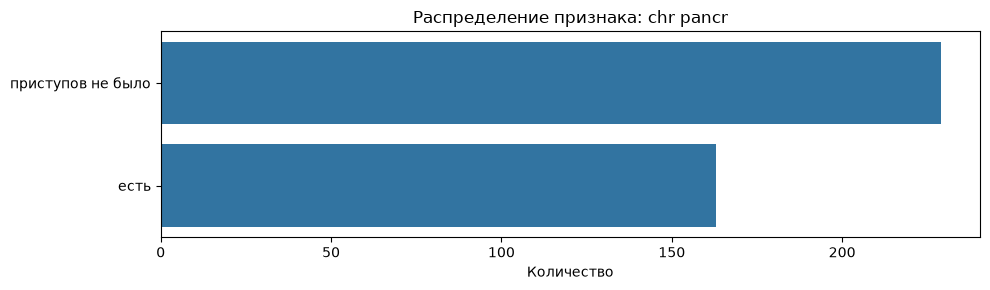

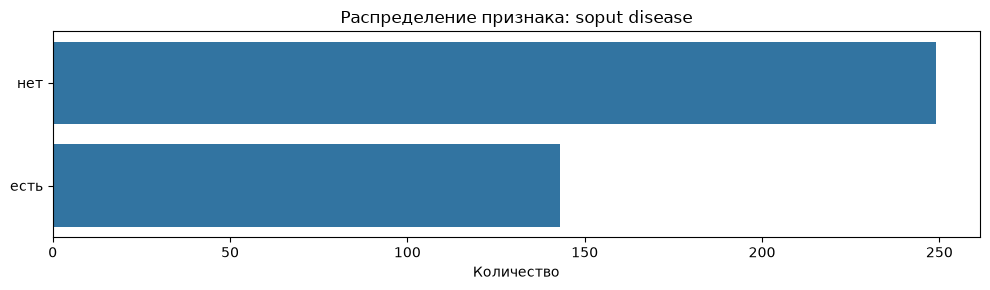

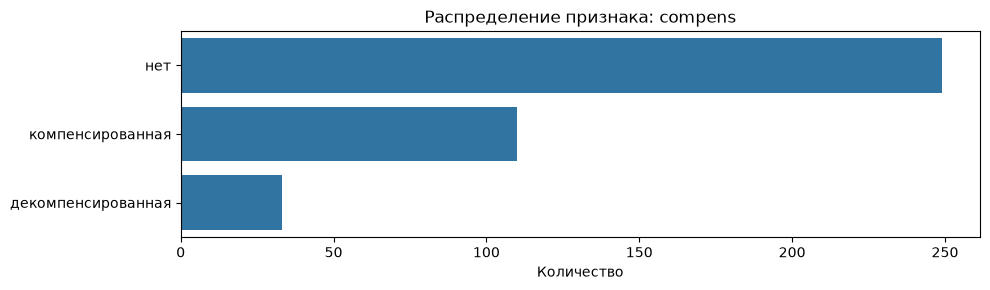

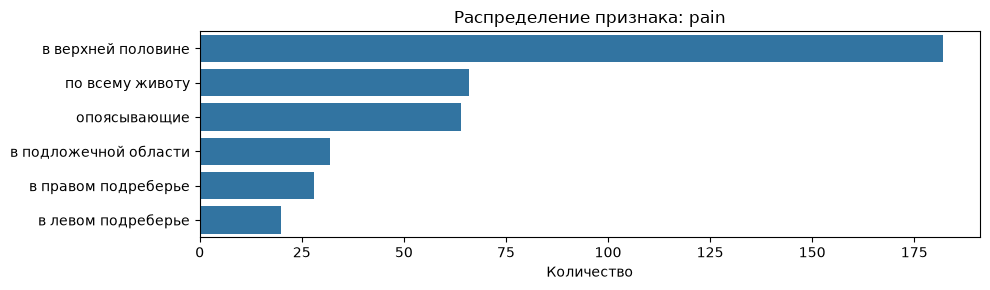

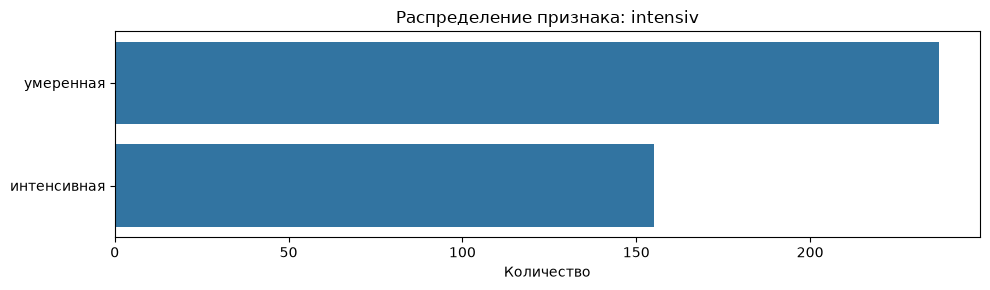

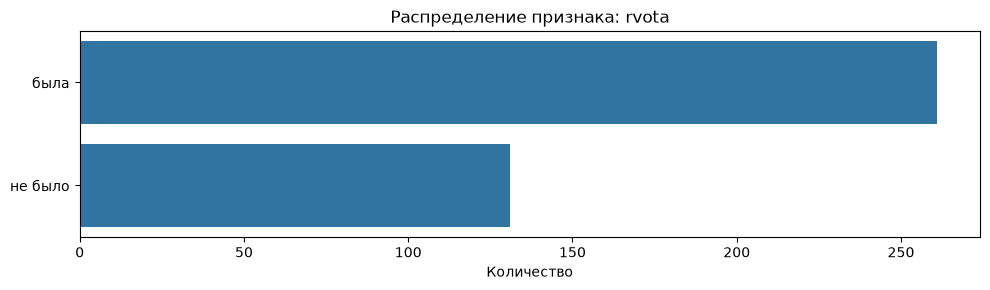

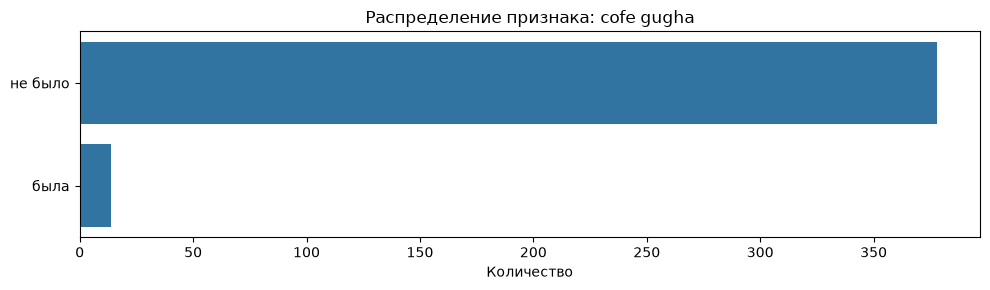

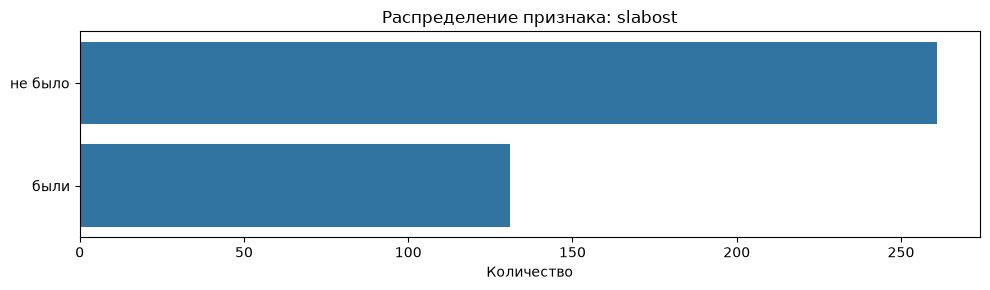

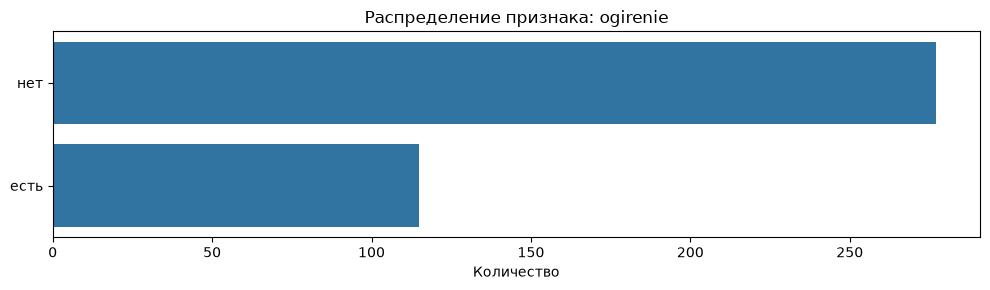

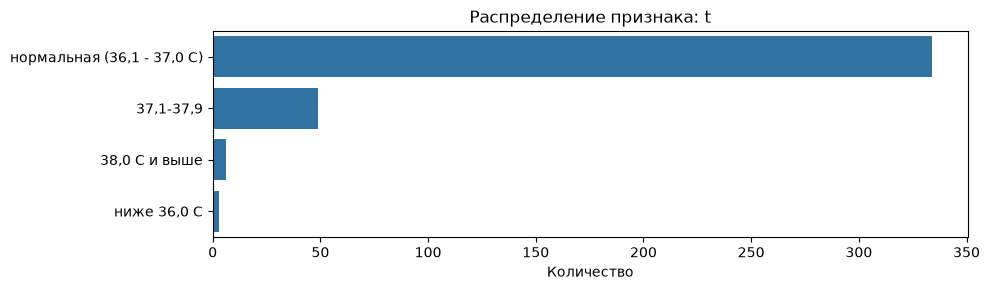

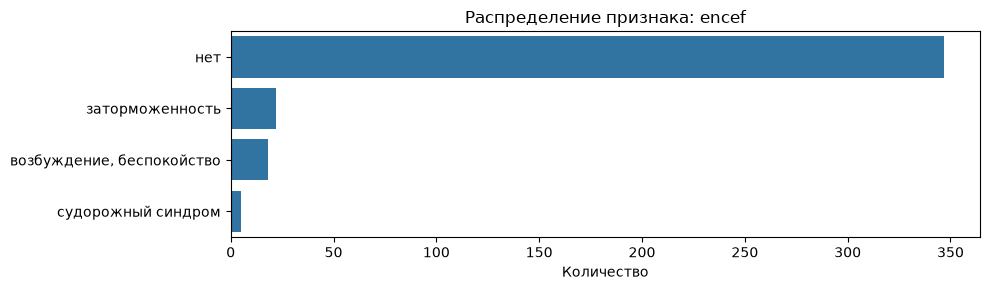

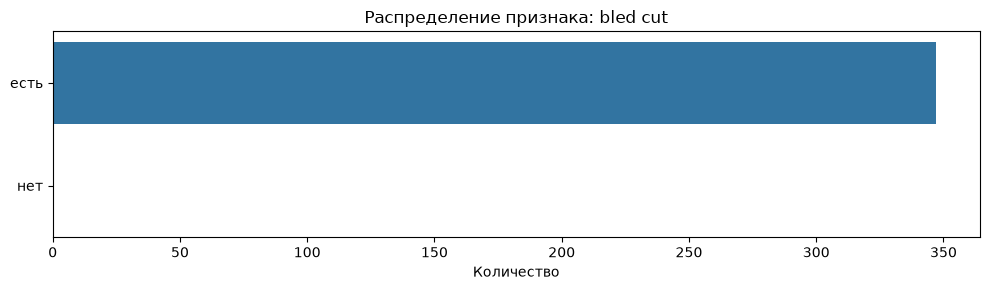

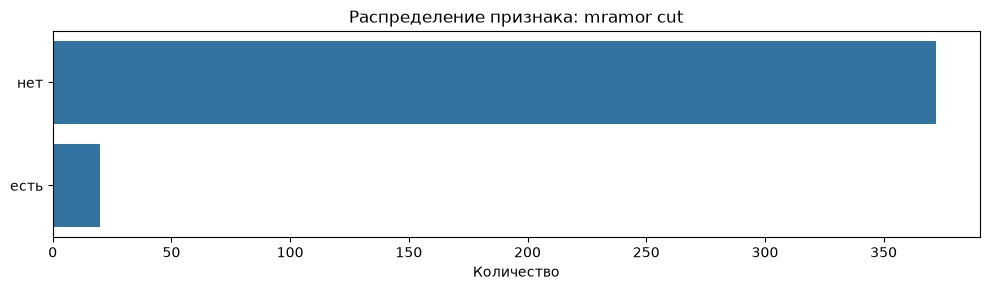

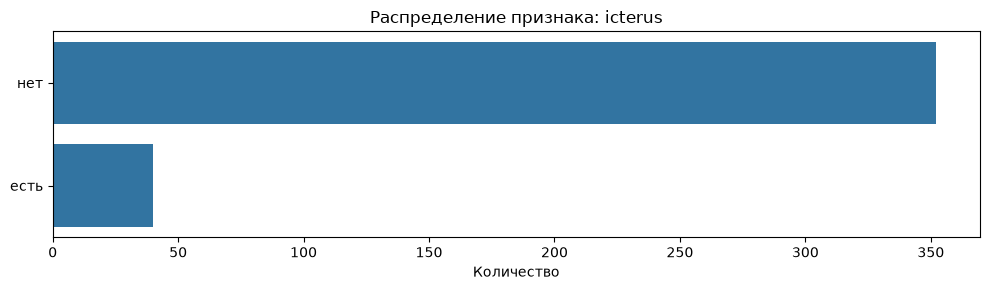

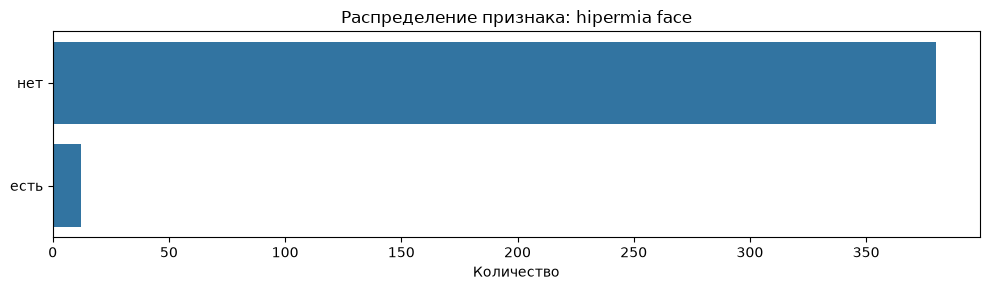

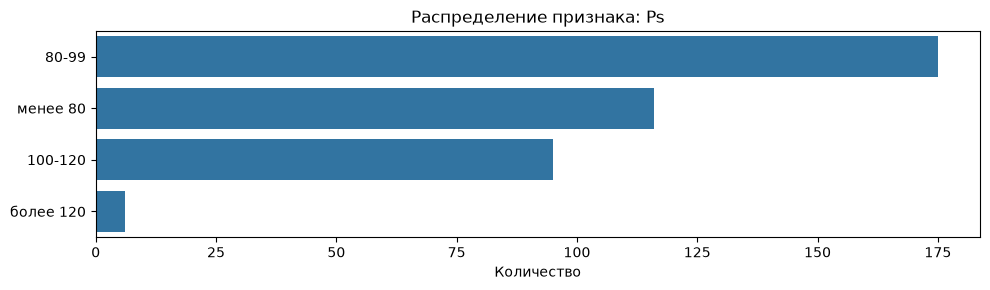

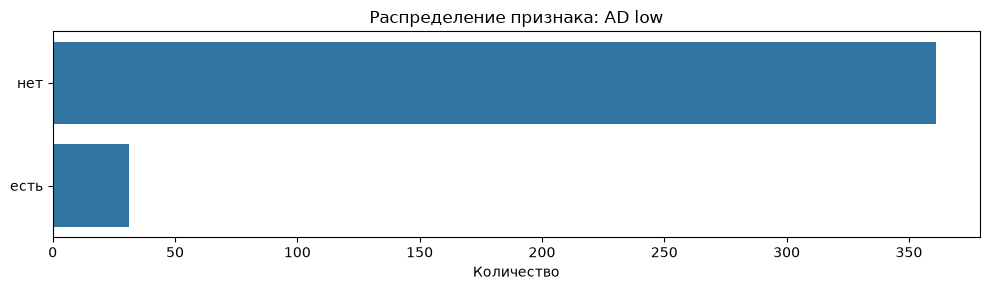

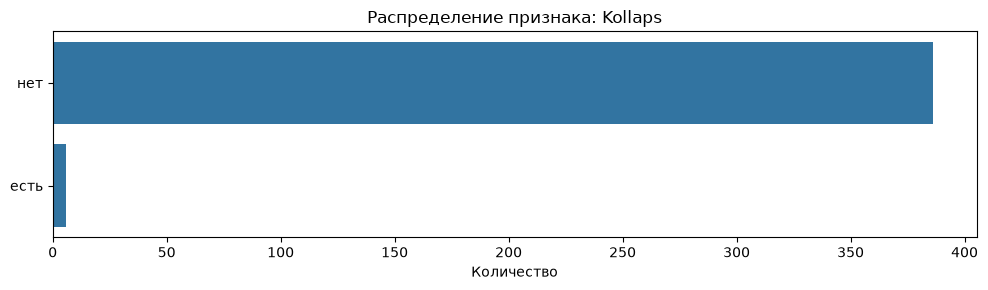

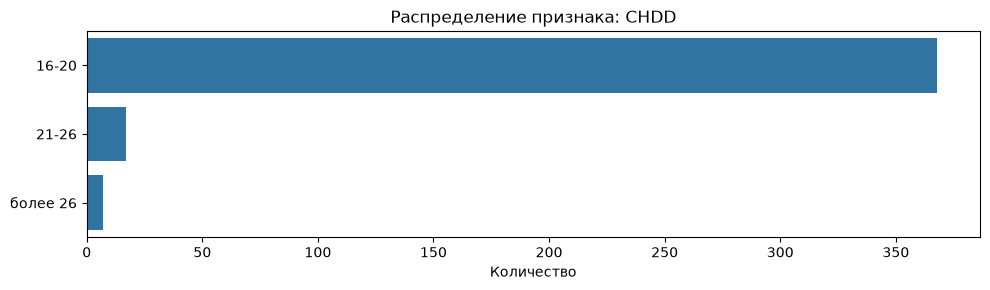

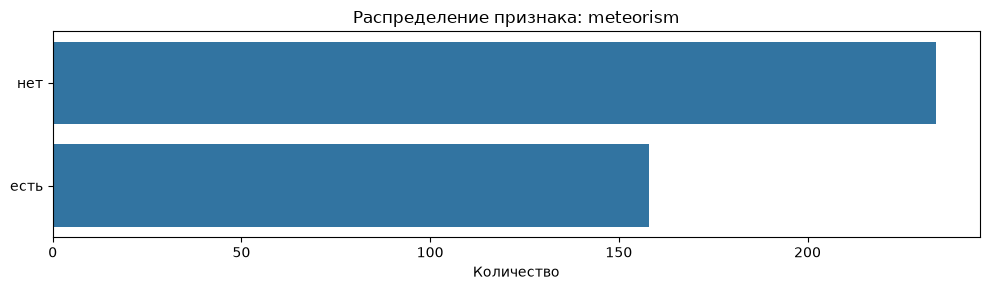

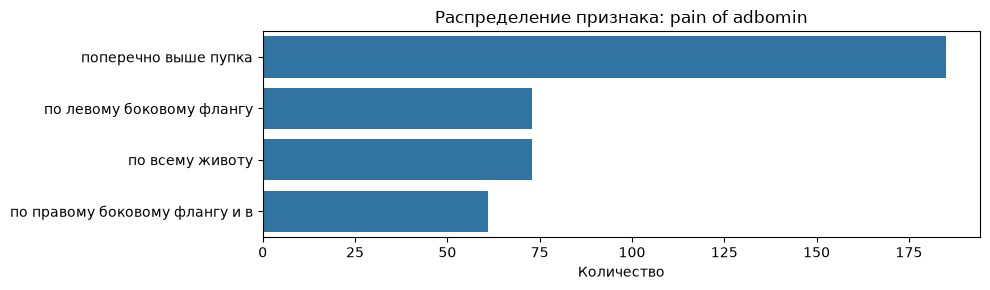

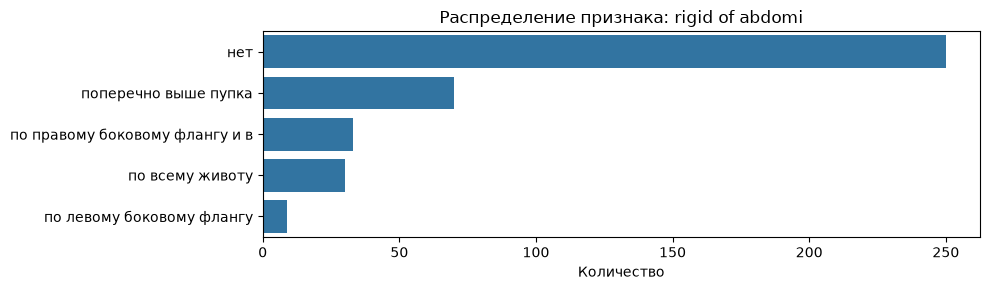

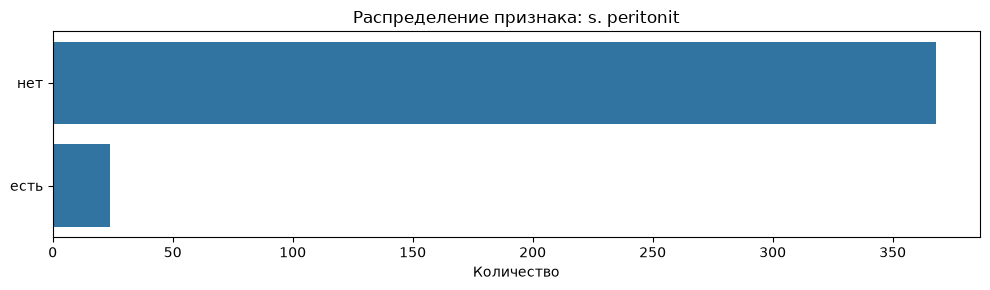

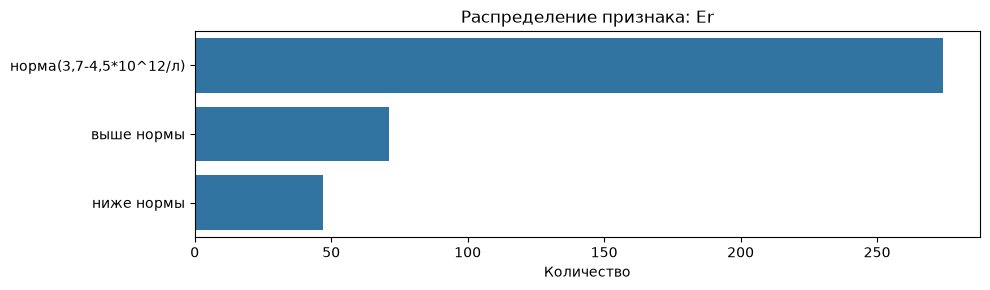

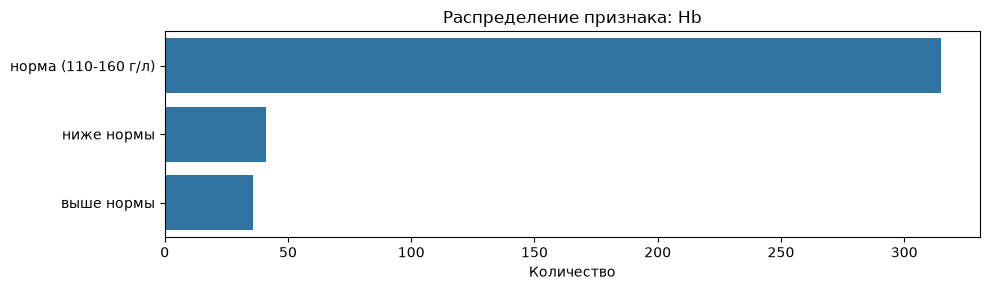

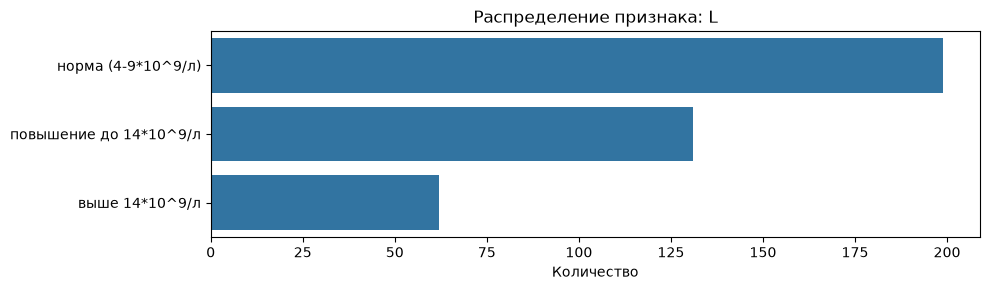

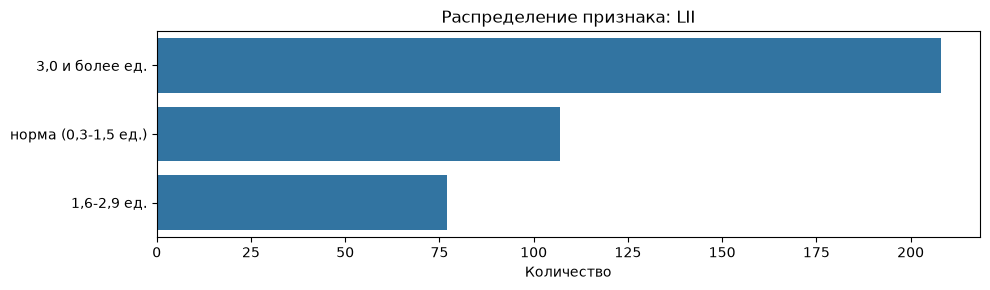

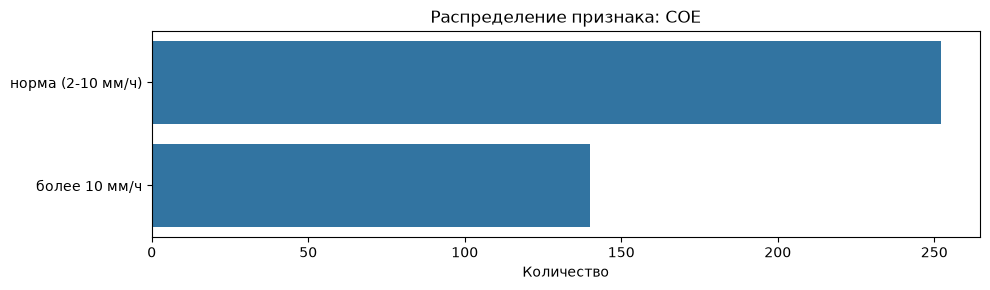

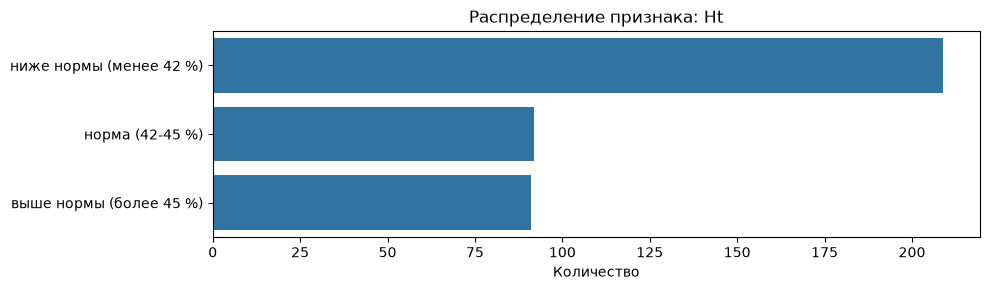

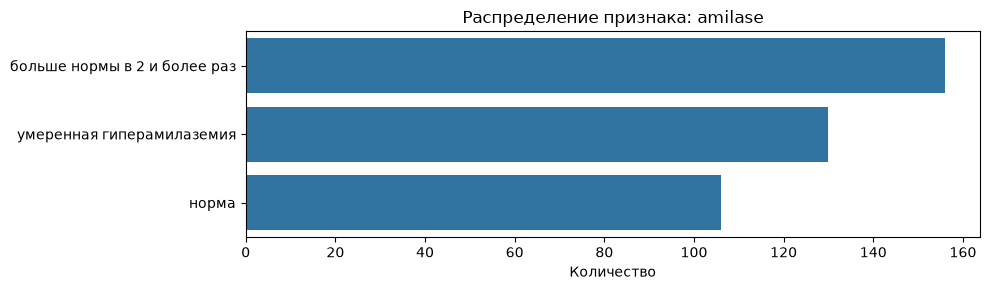

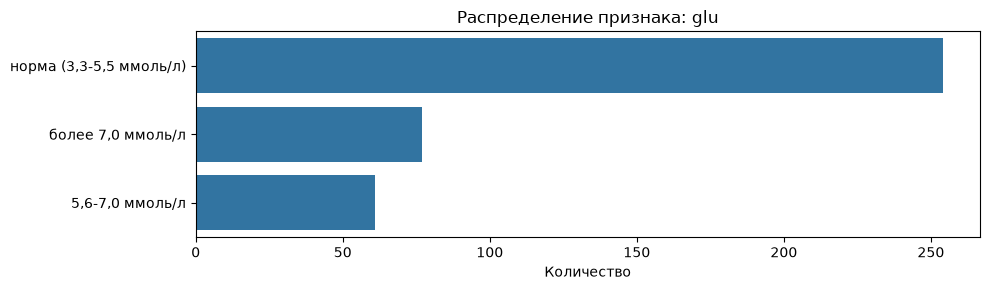

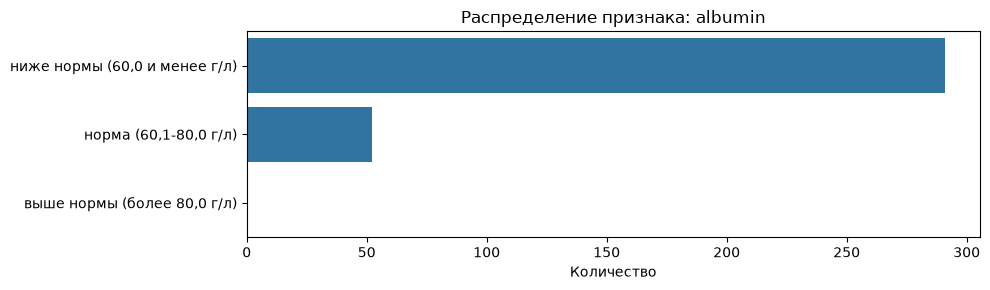

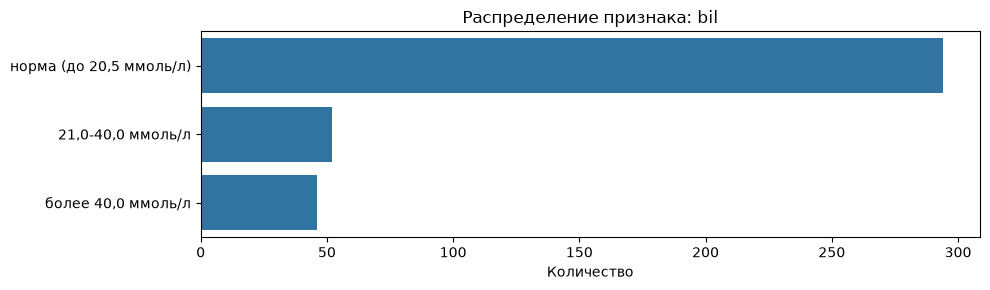

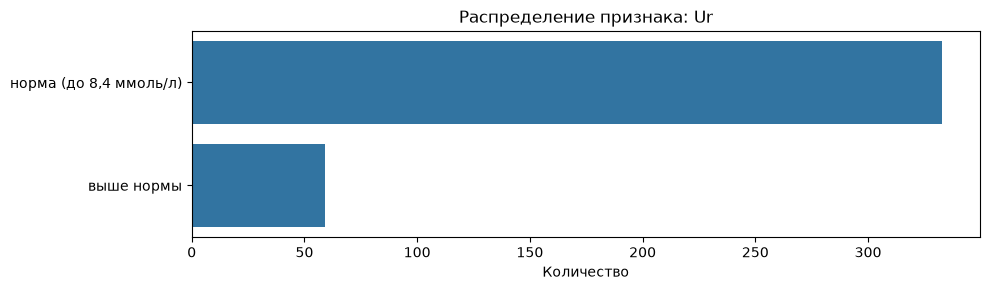

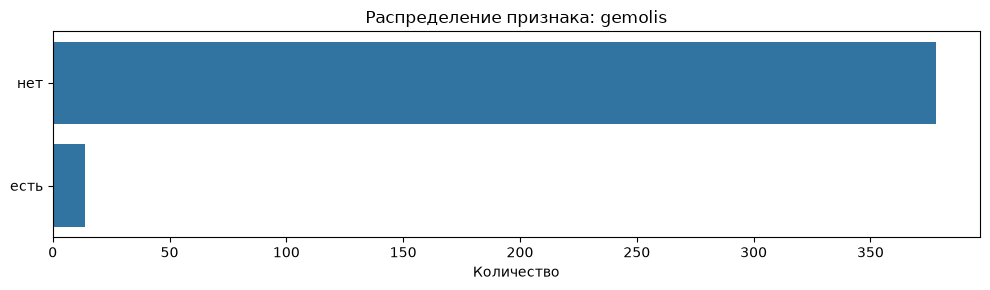

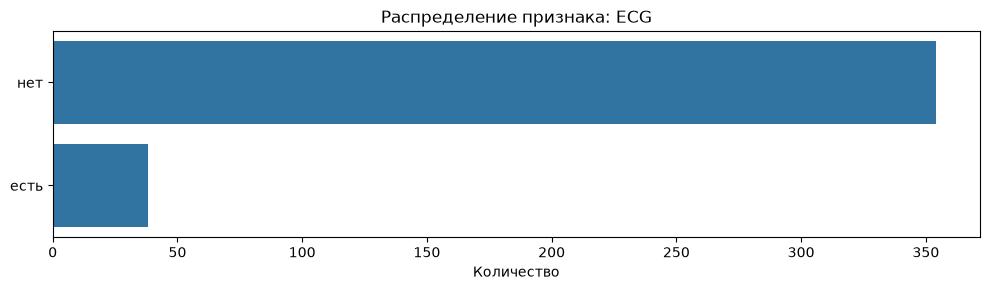

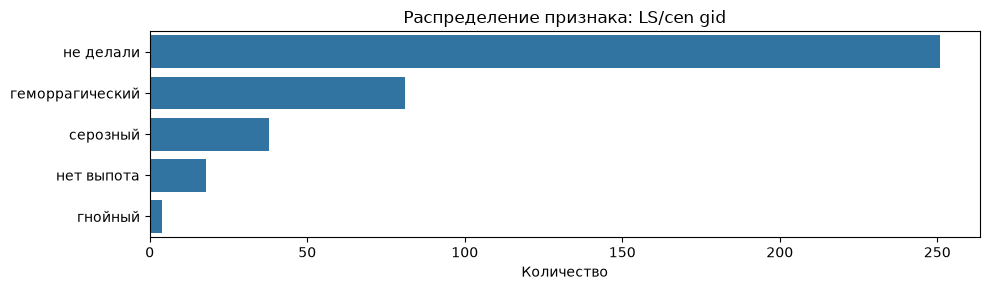

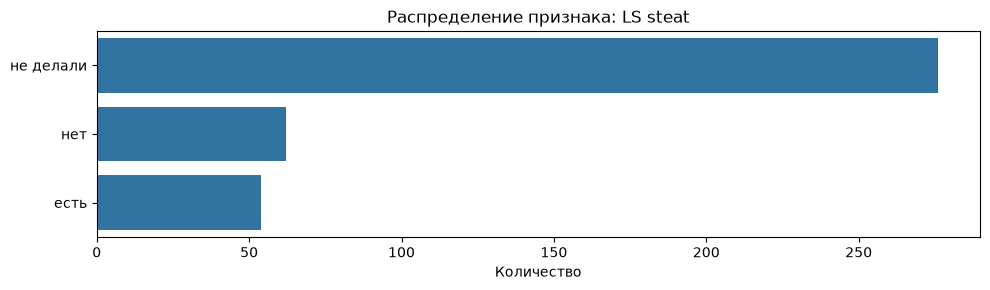

In [12]:
for col in df.columns:
    if col != target:
        plot_feature_distribution(col)

## 7. Связь признаков с целевой переменной

In [13]:
def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)
    chi2 = stats.chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape
    phi2corr = max(0, phi2 - ((k-1)*(r-1))/(n-1))
    rcorr = r - ((r-1)**2)/(n-1)
    kcorr = k - ((k-1)**2)/(n-1)
    return np.sqrt(phi2corr / min((kcorr-1), (rcorr-1)))

,feature,chi2,p_value,dof,cramers_v
22,meteorism,141.459236,1.916537e-31,2,0.597212
38,LS/cen gid,220.443965,3.102614e-43,8,0.521863
24,rigid of abdomi,197.185508,2.502506e-38,8,0.492466
35,Ur,85.574244,2.616912e-19,2,0.462313
39,LS steat,140.678448,2.020187e-29,4,0.418590
33,glu,129.559532,4.837237e-27,4,0.401202
8,intensiv,58.221834,2.276614e-13,2,0.379180
23,pain of adbomin,107.635743,6.370216e-21,6,0.360949
31,Ht,99.816952,1.076005e-20,4,0.350472
7,pain,101.286904,3.010785e-17,10,0.342057


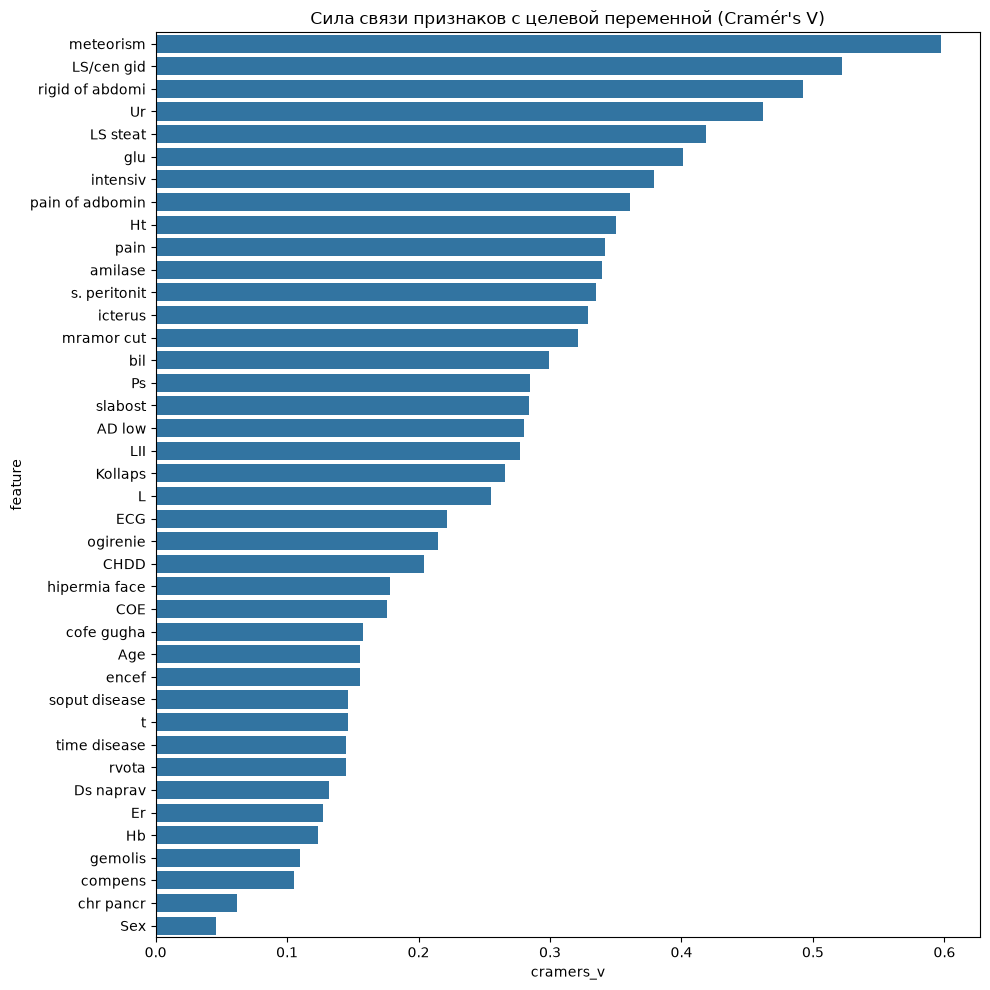

In [14]:
results = []
for col in df.columns:
    if col == target or col in ['bled cut', 'albumin']:
        continue
    ct = pd.crosstab(df[col], df[target], dropna=False)
    if ct.shape[0] < 2 or ct.shape[1] < 2:
        continue
    chi2, p, dof, expected = stats.chi2_contingency(ct)
    v = cramers_v(df[col], df[target])
    results.append({'feature': col, 'chi2': chi2, 'p_value': p, 'dof': dof, 'cramers_v': v})

results_df = pd.DataFrame(results).sort_values('cramers_v', ascending=False)
display(results_df)

plt.figure(figsize=(10, max(4, len(results_df) * 0.25)))
sns.barplot(data=results_df, x='cramers_v', y='feature')
plt.title('Сила связи признаков с целевой переменной (Cramér\'s V)')
plt.tight_layout()
plt.show()

## 8. Анализ пропусков относительно целевой переменной

In [15]:
missing_target = []
for col in df.columns:
    if col == target:
        continue
    if df[col].isna().any():
        miss_ind = df[col].isna()
        ct = pd.crosstab(miss_ind, df[target])
        if ct.shape[0] == 2 and ct.shape[1] > 1:
            chi2, p, dof, expected = stats.chi2_contingency(ct)
            missing_target.append({'feature': col, 'p_value': p, 'chi2': chi2})

missing_target_df = pd.DataFrame(missing_target).sort_values('p_value')
display(missing_target_df)
print('Пропуски, связанные с целевой переменной (p < 0.05):')
display(missing_target_df[missing_target_df['p_value'] < 0.05])

,feature,p_value,chi2
0,bled cut,0.000034,20.581450
1,albumin,0.468741,1.515408


Пропуски, связанные с целевой переменной (p < 0.05):


,feature,p_value,chi2
0,bled cut,0.000034,20.58145


## 9. Сохранение результатов

In [ ]:
REPORT_DIR = Path('_reports')
REPORT_DIR.mkdir(exist_ok=True)

missing.to_csv(REPORT_DIR / 'missing_values.csv')
uniq.to_csv(REPORT_DIR / 'unique_values.csv')
results_df.to_csv(REPORT_DIR / 'feature_target_associations.csv', index=False)
if len(missing_target_df) > 0:
    missing_target_df.to_csv(REPORT_DIR / 'missing_target_associations.csv', index=False)
print('Сохранено в', REPORT_DIR.resolve())

Сохранено в D:\Projects\OptimalMLMethod\reports
